Set 4 - Stochastic process Exercises
Ali khabazian - 402416066

Q2: simulating based on brownian motion

In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
dt = 0.01  
T = 100   
N = int(T / dt) 


D = 1.0    # Diffusion coefficient
x0 = 0.0   
v0 = 0.0   


x = np.zeros(N)
v = np.zeros(N)


x[0] = x0
v[0] = v0


for i in range(1, N):
    v[i] = v[i-1] + np.random.normal(0, np.sqrt(2*D*dt))
    x[i] = x[i-1] + v[i]*dt

In [3]:
a = np.mean(v)
b = np.mean(v**2)
c = np.correlate(v, v, mode='full')[N-1] / (N-1)
d = np.mean(x)
e = np.mean(x**2)
f = np.correlate(x, x, mode='full')[N-1] / (N-1)

In [4]:
print("a = <v(t)> =", a)
print("b = <v(t)^2> =", b)
print("c = <v(t1)v(t2)> =", c)
print("d = <x(t)> =", d)
print("e = <x(t)^2> =", e)
print("f = <x(t1)x(t2)> =", f)

a = <v(t)> = 6.836597766566051
b = <v(t)^2> = 58.34330568298496
c = <v(t1)v(t2)> = 58.349140597044666
d = <x(t)> = 293.3519234454368
e = <x(t)^2> = 132842.26079530557
f = <x(t1)x(t2)> = 132855.5463499406


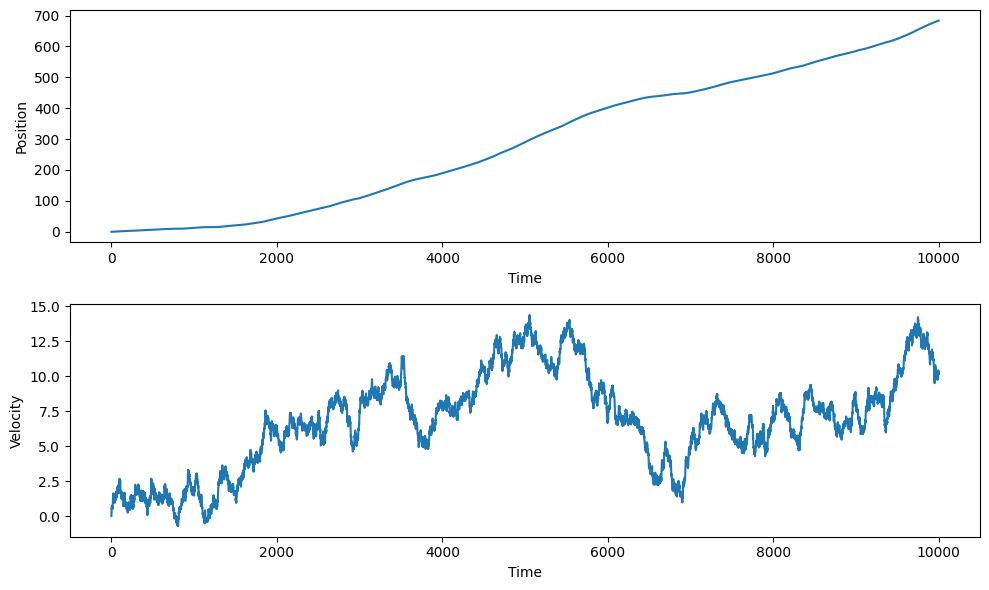

In [5]:
plt.figure(figsize=(10, 6))
plt.subplot(2, 1, 1)
plt.plot(x)
plt.xlabel('Time')
plt.ylabel('Position')
plt.subplot(2, 1, 2)
plt.plot(v)
plt.xlabel('Time')
plt.ylabel('Velocity')
plt.tight_layout()
plt.show()

Rewrite some parts without usung mean and correlate: (for part a,b,c)

In [7]:
#A
import random

def simulate_brownian_motion(steps, step_size):
    x = 0  

    for _ in range(steps):
        x += random.uniform(-step_size, step_size)

    return x

num_steps = 1000
step_size = 0.1

final_position = simulate_brownian_motion(num_steps, step_size)

print("Final position:", final_position)

average_velocity = final_position / num_steps

print("Average velocity:", average_velocity)

Final position: 0.6382177118229038
Average velocity: 0.0006382177118229037


In [16]:
#B
average_velocity = final_position / num_steps

squared_velocity_sum = 0

for _ in range(num_steps):
    velocity = random.uniform(-step_size, step_size)
    squared_velocity_sum += velocity ** 2

average_squared_velocity = squared_velocity_sum / num_steps

print("Average squared velocity (b):", average_squared_velocity)

Average squared velocity (b): 0.003267501674310014


In [20]:
#c
product_velocity_sum = 0

for _ in range(num_steps):
    velocity_t1 = random.uniform(-step_size, step_size)
    velocity_t2 = random.uniform(-step_size, step_size)
    product_velocity_sum += velocity_t1 * velocity_t2

average_product_velocity = product_velocity_sum / num_steps

print("Average product of velocities (<v(t1)v(t2)>):", average_product_velocity)

Average product of velocities (<v(t1)v(t2)>): -0.00012929615298014658


a = <v(t)> = -0.9180794949442097
b = <v(t)^2> = 14.507325282473445
c = <v(t1)v(t2)> = 0.841503376846981


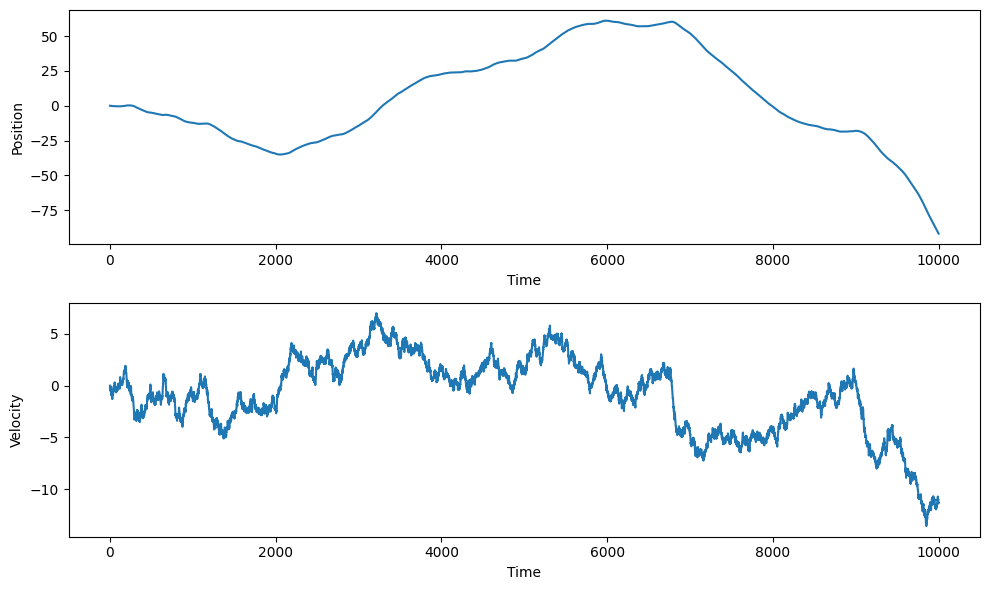

In [18]:
import numpy as np
import matplotlib.pyplot as plt

# Simulation parameters
dt = 0.01  # Time step
T = 100    # Total time
N = int(T / dt)  # Number of time steps

# Particle properties
D = 1.0    # Diffusion coefficient
x0 = 0.0   # Initial position
v0 = 0.0   # Initial velocity

# Initialize arrays
x = np.zeros(N)
v = np.zeros(N)

# Initial conditions
x[0] = x0
v[0] = v0

# Simulate Brownian motion
for i in range(1, N):
    v[i] = v[i-1] + np.random.normal(0, np.sqrt(2*D*dt))
    x[i] = x[i-1] + v[i]*dt

# Compute a = <v(t)>
a = 0
for i in range(N):
    a += v[i]
a /= N

# Compute b = <v(t)^2>
b = 0
for i in range(N):
    b += v[i]**2
b /= N

# Compute c = <v(t1)v(t2)>
c = 0
for i in range(N-1):
    for j in range(i+1, N):
        c += v[i] * v[j]
c /= (N * (N - 1) / 2)

print("a = <v(t)> =", a)
print("b = <v(t)^2> =", b)
print("c = <v(t1)v(t2)> =", c)

# Plot the position and velocity
plt.figure(figsize=(10, 6))
plt.subplot(2, 1, 1)
plt.plot(x)
plt.xlabel('Time')
plt.ylabel('Position')
plt.subplot(2, 1, 2)
plt.plot(v)
plt.xlabel('Time')
plt.ylabel('Velocity')
plt.tight_layout()
plt.show()